#### Prelimnary Analysis - Seaborn + plotly
<pre>
1) Check null values and duplicates in each df.
2) Find Count of Customers from each city and represent it on bar chart.
3) Find Range Age wise count of cutsomers, represent it on pie chart.
4) Find Count of each activity, represent it on bar chart
5) Find order month wise total amount. Represent it on line chart.
6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
7) City wise find total amount
8) Find count of each payment mode, represent it on donut chart
9) Represent Payment mode wise sum of amount on a strip plot

</pre>
#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City.

</pre>


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')  

In [3]:
ca =pd.read_csv('cust_activity.csv')
cb =pd.read_csv('cust_bio.csv')
cs=pd.read_csv('cust_sub.csv')
orders =pd.read_csv('orders.csv')
sp =pd.read_csv('sp.csv')

In [5]:
print(ca.shape)
print(cb.shape)
print(cs.shape)
print(orders.shape)
print(sp.shape)

(7500, 3)
(478, 3)
(51, 3)
(127, 4)
(6, 5)


In [6]:
print(ca.columns)
print(cb.columns)
print(cs.columns)
print(orders.columns)
print(sp.columns)

Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')


## 1) Check null values and duplicates in each df.

In [17]:
for i in [ca,cb, cs, orders, sp]:
    print(i.isnull().sum())

Cust_ID     0
Activity    0
Date        0
dtype: int64
Cust_ID    0
City       0
Age        0
dtype: int64
Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64
Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64
Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64


In [18]:
ca.isnull().sum()

Cust_ID     0
Activity    0
Date        0
dtype: int64

In [19]:
cb.isnull().sum()

Cust_ID    0
City       0
Age        0
dtype: int64

In [20]:
cs.isnull().sum()

Cust_ID          0
Plan_Var_ID      0
Purchase_Date    0
dtype: int64

In [21]:
orders.isnull().sum()

Order_id        0
Cust_ID         0
Amount          0
Payment_mode    0
dtype: int64

In [22]:
sp.isnull().sum()

Plan_Var_ID    0
Plan_ID        0
Plan_name      0
Price          0
Duration       0
dtype: int64

In [29]:
def check_dup(data):
    dup = data.duplicated().sum()
    if dup>0:
        print(dup)
    else:
        print('No Duplicates')

In [30]:
for i in [ca,cb, cs, orders, sp]:
    check_dup(i)

No Duplicates
No Duplicates
No Duplicates
No Duplicates
No Duplicates


In [34]:
!pip install plotly

In [35]:
 import plotly.express as px

## 2) Find Count of Customers from each city and represent it on bar chart.


In [38]:
q2 = cb['City'].value_counts().reset_index()
q2

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


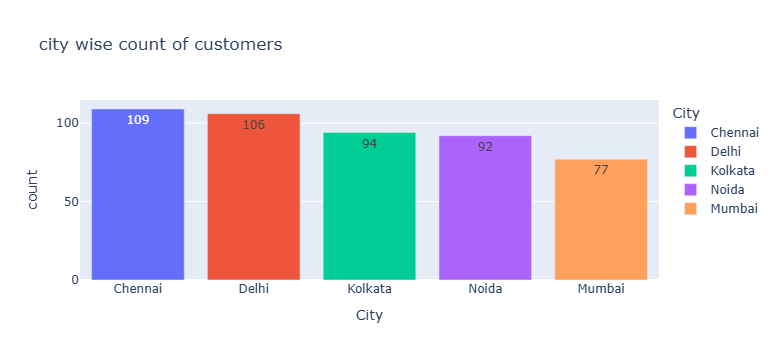

In [84]:
fig = px.bar(data_frame = q2, x='City', y='count', 
             title='city wise count of customers',text='count',color='City')
fig.show()

## text is used to show data labels

## 3) Find Range Age wise count of cutsomers, represent it on pie chart.


In [45]:
q3 = cb['Age'].value_counts().reset_index()
q3

,Age,count
0,21,34
1,34,33
2,37,32
3,32,31
4,36,30
5,35,29
6,29,29
7,27,28
8,23,28
9,31,27


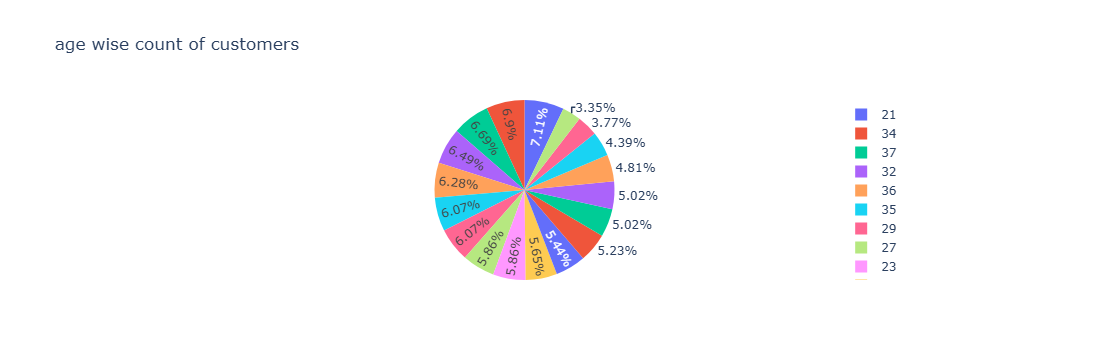

In [49]:
fig = px.pie(data_frame = q3, names='Age', values='count', 
             title='age wise count of customers',color='Age')
fig.show()

In [51]:
cb['Age_Range'] = pd.cut(cb['Age'], bins = [19, 24,29,34,39])
cb['Age_Range'] = cb['Age_Range'].astype(str)

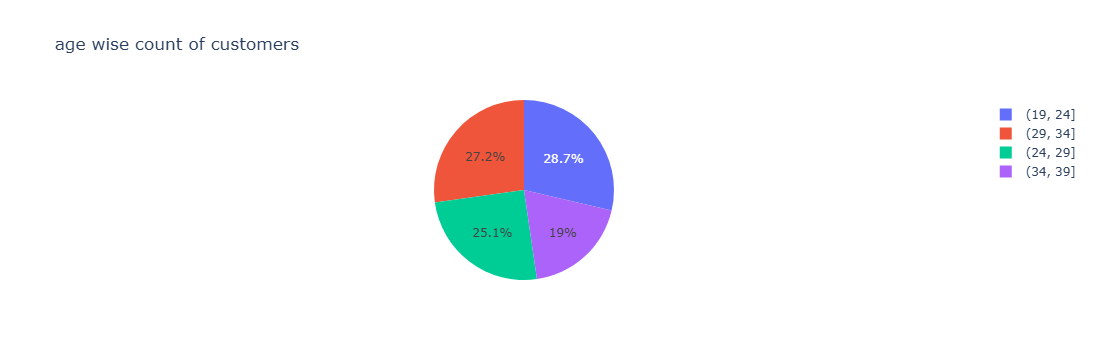

In [52]:
a3 = cb['Age_Range'].value_counts().reset_index()
a3
fig = px.pie(data_frame = a3, names='Age_Range', values='count', 
             title='age wise count of customers',color='Age_Range')
fig.show()

## 4) Find Count of each activity, represent it on bar chart

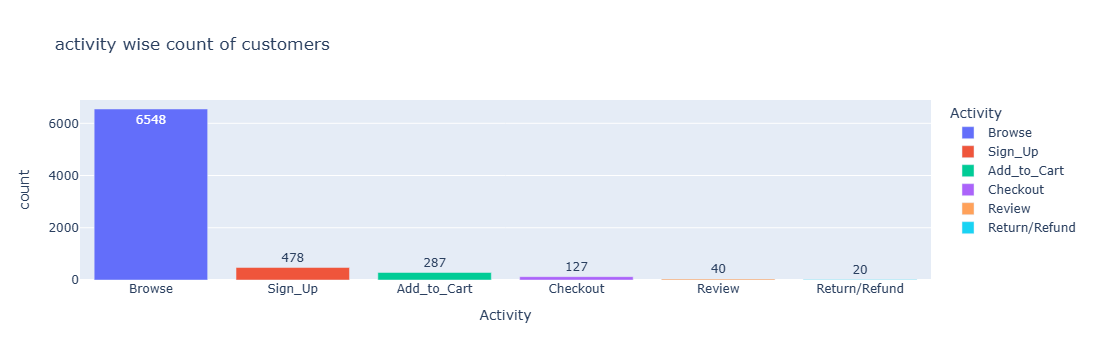

In [61]:
q4 = ca['Activity'].value_counts().reset_index()
q4
fig = px.bar(data_frame=q4, x='Activity', y='count', title='activity wise count of customers', 
             text='count', color='Activity')
fig.show()

## 5) Find order month wise total amount. Represent it on line chart.

In [69]:
print(orders.columns)
print(ca.columns)
print(orders.shape)
print(ca.shape)

Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Cust_ID', 'Activity', 'Date', 'Month'], dtype='str')
(127, 4)
(7500, 4)


In [67]:
ca['Date'] = pd.to_datetime(ca['Date'])
ca['Month'] = ca['Date'].dt.month

In [68]:
ca.head()

,Cust_ID,Activity,Date,Month
0,CUS_121,Sign_Up,2024-04-24,4
1,CUS_121,Browse,2024-04-27,4
2,CUS_121,Add_to_Cart,2024-04-27,4
3,CUS_121,Browse,2024-04-29,4
4,CUS_121,Browse,2024-04-30,4


In [72]:
ca_checkout = ca[ca['Activity']=='Checkout']
print(ca_checkout.shape) 
print(orders.shape)

(127, 4)
(127, 4)


In [74]:
ca_orders = pd.merge(orders,ca_checkout, on='Cust_ID', how='inner')
ca_orders.head()

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,Month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7
3,ORD_74,CUS_360,5736.31,COD,Checkout,2025-05-24,5
4,ORD_75,CUS_714,1592.53,Debit Card,Checkout,2024-06-19,6


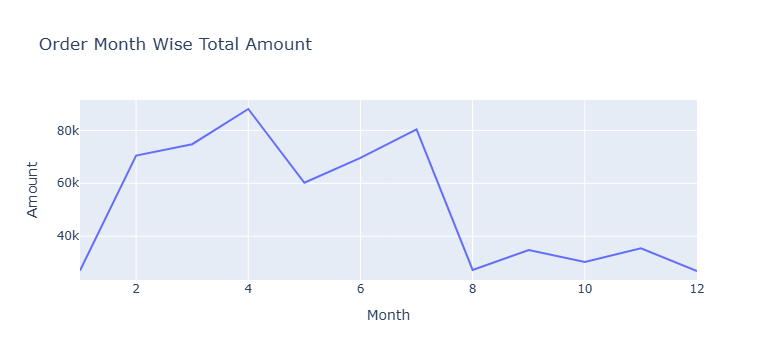

In [76]:
q5 = ca_orders.groupby('Month')['Amount'].sum().reset_index()
q5
fig = px.line(data_frame=q5, x='Month', y='Amount', title='Order Month Wise Total Amount')
fig.show()


## 6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.

In [93]:
Sub_Plan = pd.merge(cs, sp, on='Plan_Var_ID', how='inner')
q6 = Sub_Plan.groupby('Plan_name')['Price'].sum().reset_index()
q6

,Plan_name,Price
0,Diamond,54720.0
1,Gold,31200.0
2,Silver,21840.0


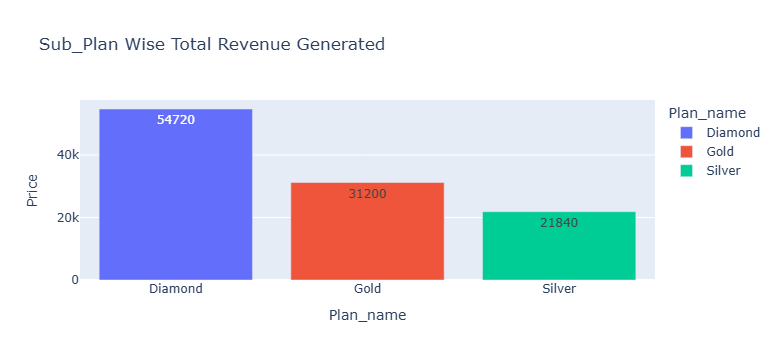

In [94]:
fig = px.bar(data_frame=q6, x='Plan_name', y='Price', 
             title='Sub_Plan Wise Total Revenue Generated', text='Price', color='Plan_name')
fig.show()

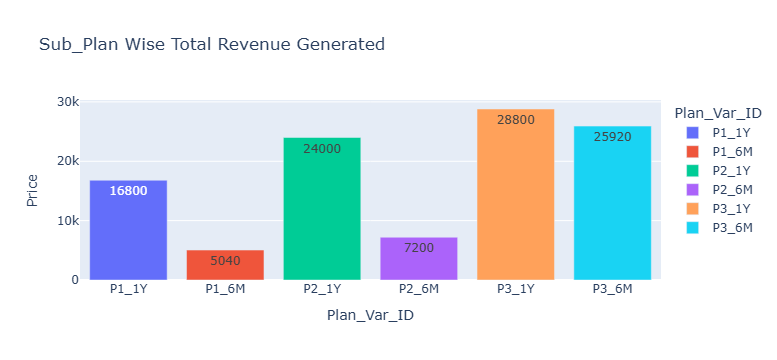

In [96]:
Sub_Plan = pd.merge(cs, sp, on='Plan_Var_ID', how='inner')
q6_1 = Sub_Plan.groupby('Plan_Var_ID')['Price'].sum().reset_index()
q6_1
fig = px.bar(data_frame=q6_1, x='Plan_Var_ID', y='Price', 
             title='Sub_Plan Wise Total Revenue Generated', text='Price', color='Plan_Var_ID')
fig.show()

## 7) City wise find total amount

In [82]:
orders_city = pd.merge(orders, cb[['Cust_ID', 'City']], on='Cust_ID', how='inner')

In [83]:
q7 = orders_city.groupby('City')['Amount'].sum().reset_index()
q7


,City,Amount
0,Chennai,96763.72
1,Delhi,147176.17
2,Kolkata,102185.83
3,Mumbai,120515.98
4,Noida,158552.95


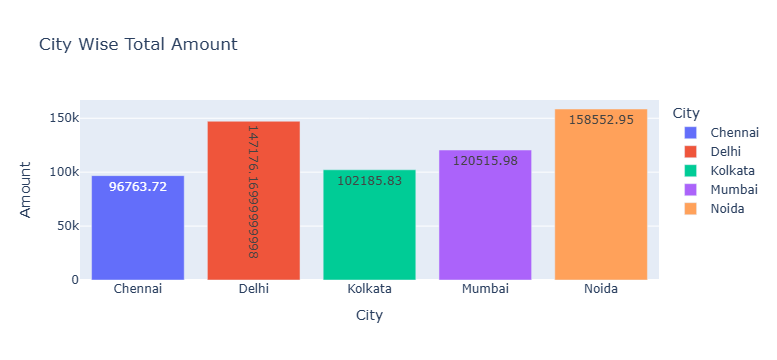

In [85]:
fig = px.bar(data_frame=q7, x='City', y='Amount', title='City Wise Total Amount', 
             text='Amount', color='City')
fig.show()

# Objective - Funnel Analysis


#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City.

</pre>


#### 1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

In [120]:
ca.head()

,Cust_ID,Activity,Date,Month
0,CUS_121,Sign_Up,2024-04-24,4
1,CUS_121,Browse,2024-04-27,4
2,CUS_121,Add_to_Cart,2024-04-27,4
3,CUS_121,Browse,2024-04-29,4
4,CUS_121,Browse,2024-04-30,4


In [121]:
ca['Activity'].value_counts()

Activity
Browse           6548
Sign_Up           478
Add_to_Cart       287
Checkout          127
Review             40
Return/Refund      20
Name: count, dtype: int64

In [122]:
w1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name='Count')
w1.head()

,Cust_ID,Activity,Count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10


In [123]:
funnel = w1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [124]:
funnel['Prev_Count'] = funnel['count'].shift(1)
funnel

,Activity,count,Prev_Count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,40.0


In [125]:
funnel['Prev_Count'] = np.where(funnel['Activity']=='Return/Refund',
                                funnel['count'].shift(2),
                                funnel['count'].shift(1))
funnel

,Activity,count,Prev_Count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [126]:
funnel['Pre_Conversion'] = round((funnel['count']/funnel['Prev_Count'])*100,2)
funnel.fillna(0,inplace=True)
funnel

,Activity,count,Prev_Count,Pre_Conversion
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


In [128]:
funnel['Pre_Conversion'] = funnel['Pre_Conversion'].apply(lambda x: str(x) + '%')
funnel

,Activity,count,Prev_Count,Pre_Conversion
0,Browse,681,0.0,0.0%
1,Sign_Up,478,681.0,70.19%
2,Add_to_Cart,287,478.0,60.04%
3,Checkout,127,287.0,44.25%
4,Review,40,127.0,31.5%
5,Return/Refund,20,127.0,15.75%


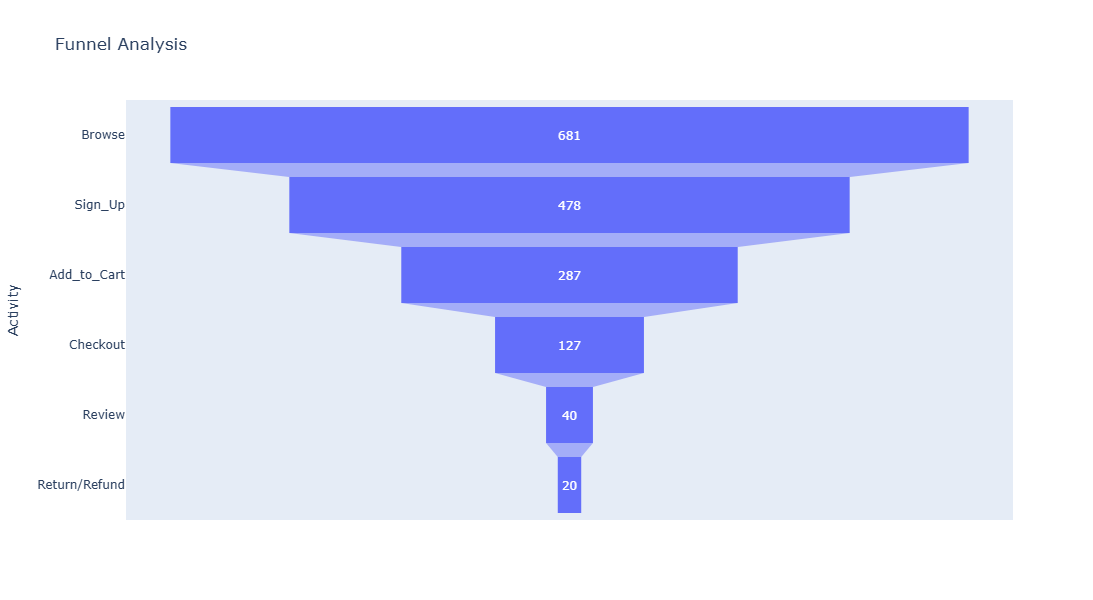

In [129]:
fig = px.funnel(data_frame=funnel, y='Activity', x='count',
                title='Funnel Analysis',height=600,hover_data='Pre_Conversion')
fig.show()

## 2) Find Count of Customers from each city and represent it on bar chart.


In [130]:
ca.head(20)

,Cust_ID,Activity,Date,Month
0,CUS_121,Sign_Up,2024-04-24,4
1,CUS_121,Browse,2024-04-27,4
2,CUS_121,Add_to_Cart,2024-04-27,4
3,CUS_121,Browse,2024-04-29,4
4,CUS_121,Browse,2024-04-30,4
5,CUS_121,Browse,2024-05-04,5
6,CUS_121,Checkout,2024-05-05,5
7,CUS_121,Browse,2024-05-07,5
8,CUS_121,Browse,2024-05-09,5
9,CUS_121,Browse,2024-05-10,5


In [134]:
pt1 = pd.pivot_table(data=ca, index=['Cust_ID'], columns=['Activity'], values='Date', aggfunc='min')
pt1.head(15)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [138]:
pt1['DD_Browse_2_Signup'] = abs((pt1['Sign_Up'] - pt1['Browse']).dt.days)
pt1['DD_Signup_2_Add2Cart'] = (pt1['Add_to_Cart'] - pt1['Sign_Up']).dt.days
pt1['DD_Add2Cart_2_Checkout'] = (pt1['Checkout'] - pt1['Add_to_Cart']).dt.days
pt1['DD_Checkout_2_Review'] = (pt1['Review'] - pt1['Add_to_Cart']).dt.days
pt1['DD_Checkout_2_Review/Refund'] = (pt1['Return/Refund'] - pt1['Checkout']).dt.days
pt1.head()

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Review/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,1.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN


In [141]:
pt2 = pt1.iloc[:-5]
pt2.head(2)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,DD_Browse_2_Signup,DD_Signup_2_Add2Cart,DD_Add2Cart_2_Checkout,DD_Checkout_2_Review,DD_Checkout_2_Review/Refund
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,3.0,8.0,NaN,NaN
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN


In [142]:
pt2.mean()

Activity
Add_to_Cart                    2024-10-05 15:08:09.198606
Browse                         2024-10-10 00:55:23.076923
Checkout                       2024-11-07 07:56:13.228346
Return/Refund                         2025-01-20 20:24:00
Review                                2024-11-11 14:24:00
Sign_Up                        2024-10-05 11:23:41.848739
DD_Browse_2_Signup                               2.512605
DD_Signup_2_Add2Cart                             2.512195
DD_Add2Cart_2_Checkout                          14.425197
DD_Checkout_2_Review                               17.025
DD_Checkout_2_Review/Refund                           3.4
dtype: object